In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("/content/Train.csv")

In [17]:
import sqlite3
conn = sqlite3.connect("traffic.db")

df.to_sql(
    "traffic_data",
    conn,
    if_exists="replace",
    index=False
)

33750

In [18]:
pd.read_sql_query(
    """
    SELECT *
    FROM traffic_data
    LIMIT 5
    """,
    conn
)

,date_time,is_holiday,air_pollution_index,humidity,wind_speed,wind_direction,visibility_in_miles,dew_point,temperature,rain_p_h,snow_p_h,clouds_all,weather_type,weather_description,traffic_volume
0,2012-10-02 09:00:00,None,121,89,2,329,1,1,288.28,0.0,0.0,40,Clouds,scattered clouds,5545
1,2012-10-02 10:00:00,None,178,67,3,330,1,1,289.36,0.0,0.0,75,Clouds,broken clouds,4516
2,2012-10-02 11:00:00,None,113,66,3,329,2,2,289.58,0.0,0.0,90,Clouds,overcast clouds,4767
3,2012-10-02 12:00:00,None,20,66,3,329,5,5,290.13,0.0,0.0,90,Clouds,overcast clouds,5026
4,2012-10-02 13:00:00,None,281,65,3,329,7,7,291.14,0.0,0.0,75,Clouds,broken clouds,4918


earlier we had

df.shape

In [19]:
pd.read_sql_query(
    """

    SELECT COUNT(*)
    FROM traffic_data

    """,
    conn
)

,COUNT(*)
0,33750


earlier we had

df["traffic_volume"].mean()

In [20]:
pd.read_sql_query(
    """
    SELECT AVG(traffic_volume) AS avg_traffic
    FROM traffic_data
    """,
    conn
)

,avg_traffic
0,3240.118163


Max traffic volume

df["traffic_volume"].max()

In [21]:
pd.read_sql_query(
    """
    SELECT MAX(traffic_volume) AS max_traffic
    FROM traffic_data
    """,
    conn
)

,max_traffic
0,7280


to get the minimum traffic volume



In [22]:
pd.read_sql_query(
    """
    SELECT MIN(traffic_volume) AS min_traffic
    FROM traffic_data
    """,
    conn
)

,min_traffic
0,0


In [24]:
pd.read_sql_query(
"""
SELECT date_time
FROM traffic_data
LIMIT 5
""",
conn
)

,date_time
0,2012-10-02 09:00:00
1,2012-10-02 10:00:00
2,2012-10-02 11:00:00
3,2012-10-02 12:00:00
4,2012-10-02 13:00:00


In [32]:
hourly = pd.read_sql_query(
    """
    SELECT date_time, AVG(traffic_volume) AS avg_traffic
    FROM traffic_data
    GROUP BY date_time
    ORDER BY date_time
    """,
    conn
)

hourly

,date_time,avg_traffic
0,2012-10-02 09:00:00,5545.0
1,2012-10-02 10:00:00,4516.0
2,2012-10-02 11:00:00,4767.0
3,2012-10-02 12:00:00,5026.0
4,2012-10-02 13:00:00,4918.0
...,...,...
28584,2017-05-17 19:00:00,3136.0
28585,2017-05-17 20:00:00,2733.0
28586,2017-05-17 21:00:00,2348.0
28587,2017-05-17 22:00:00,2194.0


In [34]:
pd.read_sql_query(
"""
SELECT *
FROM traffic_data
LIMIT 1
""",
conn
)

,date_time,is_holiday,air_pollution_index,humidity,wind_speed,wind_direction,visibility_in_miles,dew_point,temperature,rain_p_h,snow_p_h,clouds_all,weather_type,weather_description,traffic_volume
0,2012-10-02 09:00:00,None,121,89,2,329,1,1,288.28,0.0,0.0,40,Clouds,scattered clouds,5545


In [42]:
df["hour"] = pd.to_datetime(
    df["date_time"]
).dt.hour
df["day_of_week"] = pd.to_datetime(
    df["date_time"]
).dt.dayofweek

In [43]:
df.to_sql(
    "traffic_data",
    conn,
    if_exists="replace",
    index=False
)

33750

In [44]:
hourly = pd.read_sql_query(
"""
SELECT
    hour,
    AVG(traffic_volume) AS avg_traffic
FROM traffic_data
GROUP BY hour
ORDER BY hour
""",
conn
)

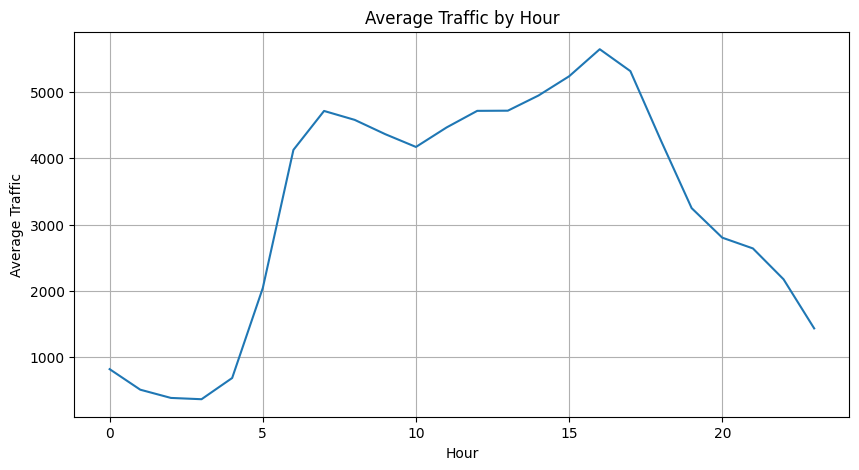

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    hourly["hour"],
    hourly["avg_traffic"]
)

plt.xlabel("Hour")
plt.ylabel("Average Traffic")
plt.title("Average Traffic by Hour")
plt.grid(True)

plt.show()

In [46]:
top_hours = pd.read_sql_query(
    """
    SELECT hour, AVG(traffic_volume) AS avg_traffic
    FROM traffic_data
    GROUP BY hour
    ORDER BY avg_traffic DESC
    LIMIT 5
    """,
    conn
)

top_hours

,hour,avg_traffic
0,16,5639.649856
1,17,5309.768202
2,15,5232.125651
3,14,4942.545061
4,13,4714.196523


In [47]:
top_hours["time"] = top_hours["hour"].apply(
    lambda x: f"{x%12 if x%12!=0 else 12} {'AM' if x<12 else 'PM'}"
)

top_hours

,hour,avg_traffic,time
0,16,5639.649856,4 PM
1,17,5309.768202,5 PM
2,15,5232.125651,3 PM
3,14,4942.545061,2 PM
4,13,4714.196523,1 PM


In [48]:
day_analysis = pd.read_sql_query(
"""
SELECT
    day_of_week,
    AVG(traffic_volume) AS avg_traffic
FROM traffic_data
GROUP BY day_of_week
ORDER BY day_of_week
""",
conn
)

day_analysis

,day_of_week,avg_traffic
0,0,3328.744153
1,1,3474.039781
2,2,3565.680665
3,3,3616.890863
4,4,3609.749843
5,5,2742.055120
6,6,2337.172898


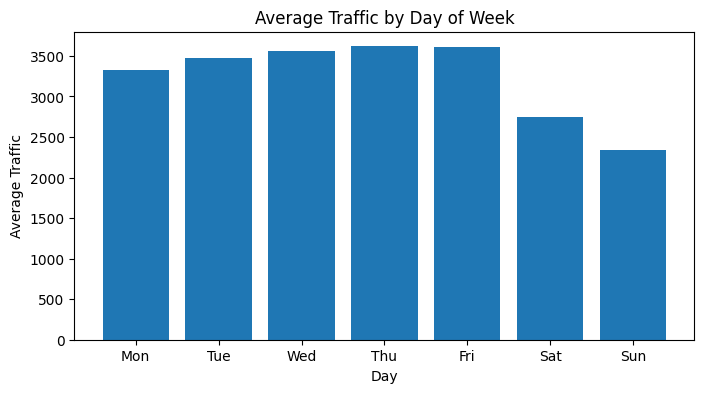

In [49]:
import matplotlib.pyplot as plt

days = [
    "Mon","Tue","Wed",
    "Thu","Fri",
    "Sat","Sun"
]

plt.figure(figsize=(8,4))

plt.bar(
    days,
    day_analysis["avg_traffic"]
)

plt.xlabel("Day")
plt.ylabel("Average Traffic")
plt.title("Average Traffic by Day of Week")

plt.show()

In [50]:
holiday_analysis = pd.read_sql_query(
"""
SELECT
    is_holiday,
    AVG(traffic_volume) AS avg_traffic,
    COUNT(*) AS records
FROM traffic_data
GROUP BY is_holiday
ORDER BY avg_traffic DESC
""",
conn
)

holiday_analysis

,is_holiday,avg_traffic,records
0,None,3243.182395,33707
1,New Years Day,1331.600000,5
2,Independence Day,1044.666667,3
3,Labor Day,1035.500000,4
4,Memorial Day,970.666667,3
5,Thanksgiving Day,855.400000,5
6,Christmas Day,774.600000,5
7,Veterans Day,661.250000,4
8,State Fair,640.333333,3
9,Washingtons Birthday,638.250000,4


In [51]:
hourly.to_sql(
    "hourly_traffic_summary",
    conn,
    if_exists="replace",
    index=False
)

24

In [52]:
day_analysis.to_sql(
    "day_traffic_summary",
    conn,
    if_exists="replace",
    index=False
)

7

In [53]:
holiday_analysis.to_sql(
    "holiday_traffic_summary",
    conn,
    if_exists="replace",
    index=False
)

12

In [54]:
peak_hour = hourly.loc[
    hourly["avg_traffic"].idxmax()
]

peak_hour

,16
hour,16.000000
avg_traffic,5639.649856


In [55]:
summary = {
    "Peak Hour": peak_hour["hour"],
    "Peak Traffic": peak_hour["avg_traffic"]
}


In [56]:
ml_data = pd.read_sql_query(
"""
SELECT *
FROM traffic_data
""",
conn
)

In [57]:
print("SQL Integration Completed")
print("Peak Hour:", peak_hour["hour"])
print("Peak Traffic:", peak_hour["avg_traffic"])

SQL Integration Completed
Peak Hour: 16.0
Peak Traffic: 5639.649855907781
